# 🚗 Análisis exploratorio: anuncios de venta de coches

En este notebook hago una primera exploración del conjunto de datos `vehicles_us.csv`, que contiene anuncios de venta de coches usados (precio, año del modelo, tipo, odómetro, etc.).

Aquí solo se construyen las dos visualizaciones base que después se usan en la aplicación web de Streamlit:

1. **Histograma** de la distribución del odómetro.
2. **Gráfico de dispersión** de la relación entre odómetro y precio.

In [1]:
import pandas as pd
import plotly.graph_objects as go

car_data = pd.read_csv('../vehicles_us.csv')
car_data.head()

,price,model_year,model,condition,cylinders,fuel,odometer,transmission,type,paint_color,is_4wd,date_posted,days_listed
0,9400,2011.0,bmw x5,good,6.0,gas,145000.0,automatic,SUV,NaN,1.0,2018-06-23,19
1,25500,NaN,ford f-150,good,6.0,gas,88705.0,automatic,pickup,white,1.0,2018-10-19,50
2,5500,2013.0,hyundai sonata,like new,4.0,gas,110000.0,automatic,sedan,red,NaN,2019-02-07,79
3,1500,2003.0,ford f-150,fair,8.0,gas,NaN,automatic,pickup,NaN,NaN,2019-03-22,9
4,14900,2017.0,chrysler 200,excellent,4.0,gas,80903.0,automatic,sedan,black,NaN,2019-04-02,28


# Análisis exploratorio: anuncios de venta de coches

Histograma del odómetro y gráfico de dispersión odómetro vs. precio.

Resorting to unclean kill browser.


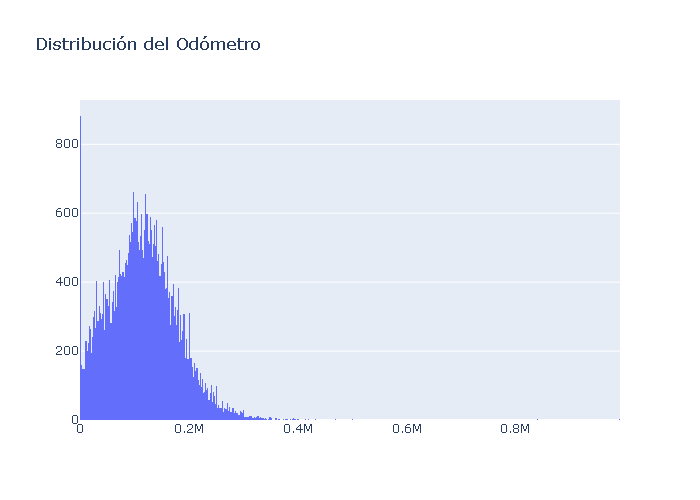

In [2]:
fig = go.Figure(data=[go.Histogram(x=car_data['odometer'])])
fig.update_layout(title_text='Distribución del Odómetro')
fig.show(renderer='png')

## 📊 Distribución del odómetro

**Qué se ve:**
- La mayoría de los coches se concentra entre aproximadamente **50 mil y 150 mil** de odómetro, con el punto más alto alrededor de las **100 mil**.
- La distribución tiene una **cola larga a la derecha**: hay pocos coches con odómetros muy altos, algunos cerca del millón.
- Hay un **pico aislado en 0**, lo que sugiere anuncios con odómetro registrado como cero (coches casi nuevos o un valor faltante capturado como 0). Valdría la pena revisarlo en un análisis más profundo.

**Por qué importa:** nos dice cuál es el odómetro "típico" de los coches en venta y avisa de valores extremos que podrían distorsionar otros análisis.

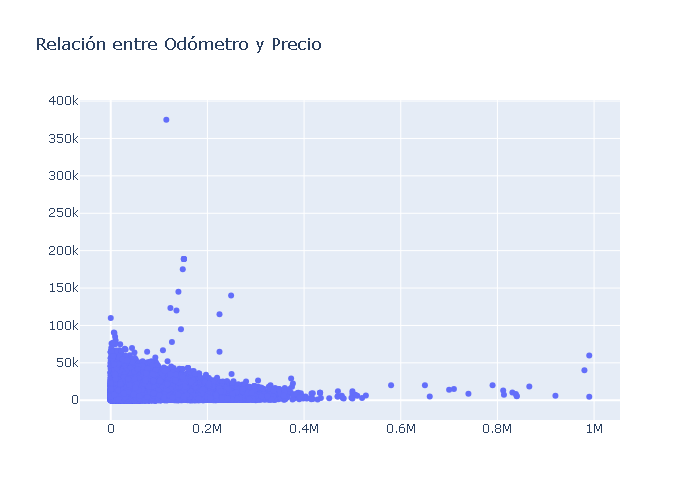

In [3]:
fig = go.Figure(data=[go.Scatter(x=car_data['odometer'], y=car_data['price'], mode='markers')])
fig.update_layout(title_text='Relación entre Odómetro y Precio')
fig.show(renderer='png')

## 📈 Relación entre odómetro y precio

**Qué se ve:**
- Hay una **tendencia a la baja**: a mayor odómetro, el precio tiende a ser menor, lo cual tiene sentido para coches usados.
- La mayoría de los anuncios se amontona en precios **por debajo de 100 mil**, en la parte izquierda de la gráfica.
- Aparecen varios **valores atípicos (outliers)**: algunos coches con precios muy altos (hasta cerca de 375 mil) y otros con odómetros cercanos al millón.

**Por qué importa:** confirma que el odómetro influye en el precio, pero no lo explica todo, ya que hay mucha dispersión y puntos raros que habría que investigar.

## ✅ Conclusiones

- El odómetro de los coches en venta se concentra en un rango medio, con una cola de valores extremos.
- A mayor odómetro, menor precio en general, aunque con mucha variabilidad.
- Hay valores atípicos y posibles datos faltantes que se tendrían que limpiar antes de un análisis más serio.

> El enfoque de este proyecto es construir y desplegar la aplicación web, así que este EDA se queda en lo básico. Las gráficas de este notebook se replican de forma interactiva en el dashboard de Streamlit.